# NLP Assignment: Dictionary-based NER and Unigram Language Model

| Problem | Dataset | Topic |
|---|---|---|
| 1 | CoNLL-2003 | Automatic dictionary construction + longest-phrase matching NER |
| 2 | CoNLL-2003 | Case-sensitive vs case-insensitive dictionary NER (+ a precision-filter extension) |
| 3 | WikiText-2 | Unigram frequency model |


**Evaluation protocol (used in Problems 1 and 2):**
* Gold labels come from the CoNLL-2003 BIO tags. Spans are decoded robustly (handles both IOB1 and IOB2).
* Only **PER, LOC, ORG** are evaluated. MISC is not part of the task, so MISC gold entities are ignored. A prediction that lands on a MISC entity is therefore counted as a **false positive**.
* **Entity-level exact match:** a prediction is a true positive only if `(sentence, start, end, type)` all match a gold entity.
* Micro-averaged P/R/F1 overall, plus per-type scores.
* Dictionaries are built from the **train** split only. The 200 evaluation sentences come from the **test** split and exclude any sentence that also appears verbatim in train.

## 0. Setup

In [1]:
%pip install -q datasets
import re, random, os, math
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from datasets import load_dataset

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
SEED = 42
random.seed(SEED); np.random.seed(SEED)

TARGET = ["PER", "LOC", "ORG"]
FULLNAME = {"PER": "PERSON", "LOC": "LOCATION", "ORG": "ORGANIZATION"}

## 1. Load CoNLL-2003 (shared by Problems 1 and 2)

The loader tries several Hugging Face mirrors (some older script-based versions no longer work with new `datasets` releases). If all fail, it asks you to upload `train.txt` and `test.txt` in the standard CoNLL format (`word POS chunk NER` per line, blank line between sentences).

In [2]:
def _from_hf():
    last = None
    for name in ["tomaarsen/conll2003", "eriktks/conll2003", "conll2003"]:
        try:
            ds = load_dataset(name)
            names = ds["train"].features["ner_tags"].feature.names
            conv = lambda split: [(list(ex["tokens"]), [names[t] for t in ex["ner_tags"]]) for ex in ds[split]]
            print(f"Loaded CoNLL-2003 from '{name}'")
            return conv("train"), conv("test")
        except Exception as e:
            last = e
            print(f"  could not load '{name}': {type(e).__name__}")
    raise RuntimeError(f"All HF mirrors failed: {last}")

def _read_conll_txt(path):
    sents, toks, tags = [], [], []
    for line in open(path, encoding="utf-8"):
        line = line.strip()
        if not line:
            if toks: sents.append((toks, tags)); toks, tags = [], []
            continue
        parts = line.split()
        if parts[0] == "-DOCSTART-": continue
        toks.append(parts[0]); tags.append(parts[-1])
    if toks: sents.append((toks, tags))
    return sents

def load_conll():
    try:
        return _from_hf()
    except Exception as e:
        print("Falling back to manual upload...")
        from google.colab import files
        up = files.upload()   # upload train.txt and test.txt
        return _read_conll_txt("train.txt"), _read_conll_txt("test.txt")

train_all, test_all = load_conll()
# drop document separators / empty sentences if any are present
train_sents = [s for s in train_all if s[0] and s[0][0] != "-DOCSTART-"]
test_pool   = [s for s in test_all  if s[0] and s[0][0] != "-DOCSTART-"]
print(f"Train sentences: {len(train_sents)} | Test pool sentences: {len(test_pool)}")

README.md:   0%|          | 0.00/15.0k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/13.5k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.24MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  316kB            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

Loaded CoNLL-2003 from 'tomaarsen/conll2003'
Train sentences: 14041 | Test pool sentences: 3453


## 2. Shared utilities: span decoding, dictionary building, longest-phrase matching, evaluation

* `bio_to_spans` converts BIO tags into `(start, end, type)` spans (end exclusive).
* **Unique dictionaries** are Python `set`s of token tuples, one set per type.
* A phrase can occur under several types (e.g. *"Germany"* as LOC and as an ORG sports team). To keep the matcher deterministic, each phrase is assigned the type it had **most often in training** (ties broken PER > LOC > ORG). The ambiguity is counted and reported.
* **Longest-phrase matching:** scan left to right; at each position try the longest possible phrase first (down to length 1). On a hit, emit the entity and jump past it; otherwise advance one token. Matches therefore never overlap.

In [3]:
def bio_to_spans(tags):
    """BIO/IOB -> list of (start, end_exclusive, type). Robust to I- tags without a preceding B-."""
    spans, start, typ = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):          # sentinel flushes the last span
        if t == "O":
            if start is not None:
                spans.append((start, i, typ)); start, typ = None, None
            continue
        prefix, etype = t.split("-", 1)
        if start is not None and (prefix == "B" or etype != typ):
            spans.append((start, i, typ)); start = None
        if start is None:
            start, typ = i, etype
    return spans

def build_phrase_counts(sents):
    """Extract every annotated PER/LOC/ORG phrase from training data with its frequency."""
    counts = {t: Counter() for t in TARGET}
    for toks, tags in sents:
        for s, e, t in bio_to_spans(tags):
            if t in counts:
                counts[t][tuple(toks[s:e])] += 1
    return counts

def build_lookup(counts, lower=False):
    """phrase -> type. Resolves cross-type ambiguity by training frequency."""
    agg = defaultdict(Counter)
    for t, c in counts.items():
        for phrase, n in c.items():
            key = tuple(w.lower() for w in phrase) if lower else phrase
            agg[key][t] += n
    lookup = {}
    for key, c in agg.items():
        lookup[key] = max(c.items(), key=lambda kv: (kv[1], -TARGET.index(kv[0])))[0]
    n_ambiguous = sum(1 for c in agg.values() if len(c) > 1)
    return lookup, n_ambiguous

def longest_match(tokens, lookup, max_len, lower=False):
    toks = [w.lower() for w in tokens] if lower else list(tokens)
    preds, i, n = [], 0, len(toks)
    while i < n:
        hit = False
        for L in range(min(max_len, n - i), 0, -1):          # longest phrase first
            key = tuple(toks[i:i + L])
            if key in lookup:
                preds.append((i, i + L, lookup[key]))
                i += L; hit = True
                break
        if not hit:
            i += 1
    return preds

def prf(tp, npred, ngold):
    p = tp / npred if npred else 0.0
    r = tp / ngold if ngold else 0.0
    f = 2 * p * r / (p + r) if (p + r) else 0.0
    return p, r, f

def evaluate(gold, pred):
    """gold, pred: sets of (sent_id, start, end, type). Returns overall + per-type table."""
    rows = []
    for name, types in [(t, [t]) for t in TARGET] + [("OVERALL (micro)", TARGET)]:
        g = {x for x in gold if x[3] in types}
        p = {x for x in pred if x[3] in types}
        tp = len(g & p)
        P, R, F = prf(tp, len(p), len(g))
        rows.append({"Type": FULLNAME.get(name, name), "Gold": len(g), "Predicted": len(p), "Correct (TP)": tp,
                     "FP": len(p) - tp, "FN": len(g) - tp, "Precision": P, "Recall": R, "F1": F})
    return pd.DataFrame(rows)

def run_ner(sentences, lookup, lower):
    max_len = max(len(k) for k in lookup)
    out = set()
    for sid, (toks, _) in enumerate(sentences):
        for s, e, t in longest_match(toks, lookup, max_len, lower):
            out.add((sid, s, e, t))
    return out

## 3. Select 200 unseen test sentences
200 sentences are drawn at random (seed 42) from the CoNLL **test** split. Any test sentence that also appears verbatim in the training split is removed from the pool first, so there is no train/test overlap. The same 200 sentences are reused in Problem 2. The check below asserts zero overlap.

In [4]:
rng = random.Random(SEED)
train_text = {tuple(t) for t, _ in train_sents}
clean_pool = [s for s in test_pool if tuple(s[0]) not in train_text]
print(f"Test pool: {len(test_pool)} | removed (verbatim also in train): {len(test_pool) - len(clean_pool)} | clean pool: {len(clean_pool)}")

test_idx = rng.sample(range(len(clean_pool)), 200)
test_sents = [clean_pool[i] for i in test_idx]

leak = sum(tuple(t) in train_text for t, _ in test_sents)
assert leak == 0, "train/test leakage detected"
print(f"Test sentences: {len(test_sents)} | verbatim overlap with training: {leak}")

gold_all = {(sid, s, e, t) for sid, (toks, tags) in enumerate(test_sents) for s, e, t in bio_to_spans(tags)}
gold = {g for g in gold_all if g[3] in TARGET}
print("Gold entities in sample (PER/LOC/ORG):", len(gold), "| MISC entities (ignored):", len(gold_all) - len(gold))
print(Counter(g[3] for g in gold))

Test pool: 3453 | removed (verbatim also in train): 126 | clean pool: 3327
Test sentences: 200 | verbatim overlap with training: 0
Gold entities in sample (PER/LOC/ORG): 284 | MISC entities (ignored): 39
Counter({'ORG': 111, 'LOC': 94, 'PER': 79})


### Error-analysis helpers
Each false positive is categorised automatically against the full gold annotation (including MISC):
* **Type confusion**: the exact span is a gold entity but with a different type (or MISC),
* **Boundary error**: it overlaps a gold entity without matching its span,
* **Spurious**: no gold entity at that position (the dictionary matched an ordinary word/phrase).

In [5]:
gold_by_sent = defaultdict(list)
for sid, s, e, t in gold_all:
    gold_by_sent[sid].append((s, e, t))

def categorize(sid, s, e, t):
    for gs, ge, gt in gold_by_sent[sid]:
        if (gs, ge) == (s, e) and gt != t:
            return "Type confusion", f"gold type = {gt}"
    for gs, ge, gt in gold_by_sent[sid]:
        if gs < e and s < ge:
            return "Boundary error", f"overlaps gold '{' '.join(test_sents[sid][0][gs:ge])}' [{gt}]"
    return "Spurious", "no gold entity here (ordinary word/phrase matched)"

ERR_COLS = ["Sent", "Predicted", "Pred type", "Error category", "Detail", "Sentence"]

def error_table(pred_set, only=None):
    fps = sorted(pred_set - gold)
    if only is not None: fps = [x for x in fps if x in only]
    rows = []
    for sid, s, e, t in fps:
        toks = test_sents[sid][0]
        ctx = " ".join(toks[:s] + ["[[" + " ".join(toks[s:e]) + "]]"] + toks[e:])
        cat, det = categorize(sid, s, e, t)
        rows.append({"Sent": sid, "Predicted": " ".join(toks[s:e]), "Pred type": t,
                     "Error category": cat, "Detail": det, "Sentence": ctx[:160]})
    return pd.DataFrame(rows, columns=ERR_COLS)

# Problem 1: Automatic dictionary construction for NER

### 1.1 Extract annotated phrases and build the three unique dictionaries

In [6]:
counts = build_phrase_counts(train_sents)
dictionaries = {t: set(c) for t, c in counts.items()}          # unique phrases only

size_df = pd.DataFrame({
    "Dictionary": [FULLNAME[t] for t in TARGET],
    "Unique phrases": [len(dictionaries[t]) for t in TARGET],
    "Total annotated mentions in train": [sum(counts[t].values()) for t in TARGET],
    "Max phrase length (tokens)": [max(len(p) for p in dictionaries[t]) for t in TARGET],
})
display(size_df)

lookup_cs, n_amb = build_lookup(counts, lower=False)
print(f"Combined lookup size: {len(lookup_cs)} | phrases present under >1 type (ambiguous): {n_amb}")
for t in TARGET:
    print(f"{FULLNAME[t]:13s} sample entries:", [" ".join(p) for p in list(dictionaries[t])[:8]])

,Dictionary,Unique phrases,Total annotated mentions in train,Max phrase length (tokens)
0,PERSON,3614,6600,6
1,LOCATION,1332,7140,10
2,ORGANIZATION,2403,6321,10


Combined lookup size: 7223 | phrases present under >1 type (ambiguous): 121
PERSON        sample entries: ['Alain Juppe', 'Newcombe', 'Stefan Edberg', 'Jose Maria Aznar', 'Norris', 'Wouden', 'Timothy Reid', 'Chiluba']
LOCATION      sample entries: ['ZIMBABWE', 'United States', 'Newark', 'North Yemen', 'Pennsylvania', 'Tripoli', 'ST HELENS', 'Middle East']
ORGANIZATION  sample entries: ['Arkansas State Police', 'Benevolent Assoc .', 'Brann', 'Defence Ministry', 'Tass', 'The Land is Ours', 'Gazeta Shqiptare', 'Brann Bergen']


### 1.2 Apply longest-phrase matching on the 200 test sentences

In [7]:
pred1 = run_ner(test_sents, lookup_cs, lower=False)
tp1   = pred1 & gold

def show(span_set, n=None):
    rows = []
    for sid, s, e, t in sorted(span_set):
        rows.append({"Sent": sid, "Entity": " ".join(test_sents[sid][0][s:e]), "Type": FULLNAME[t], "Span": f"[{s},{e})"})
    df = pd.DataFrame(rows)
    return df if n is None else df.head(n)

print(f"Predicted entities: {len(pred1)} | Correctly identified: {len(tp1)}")
print("\n--- Predicted entities (first 25 of %d; full list saved to predicted_entities_p1.csv) ---" % len(pred1))
display(show(pred1, 25))
show(pred1).to_csv("predicted_entities_p1.csv", index=False)

print("--- Correctly identified entities (first 25 of %d) ---" % len(tp1))
display(show(tp1, 25))

Predicted entities: 176 | Correctly identified: 130

--- Predicted entities (first 25 of 176; full list saved to predicted_entities_p1.csv) ---


,Sent,Entity,Type,Span
0,0,Norway,LOCATION,"[4,5)"
1,1,MINNESOTA,ORGANIZATION,"[0,1)"
2,4,Nairobi,LOCATION,"[8,9)"
3,4,Goma,LOCATION,"[41,42)"
4,5,LONDON,LOCATION,"[0,1)"
5,7,MSV Duisburg,ORGANIZATION,"[0,2)"
6,8,The,LOCATION,"[0,1)"
7,9,MIAMI,LOCATION,"[0,1)"
8,10,England,LOCATION,"[12,13)"
9,11,Des,PERSON,"[1,2)"


--- Correctly identified entities (first 25 of 130) ---


,Sent,Entity,Type,Span
0,0,Norway,LOCATION,"[4,5)"
1,1,MINNESOTA,ORGANIZATION,"[0,1)"
2,4,Nairobi,LOCATION,"[8,9)"
3,4,Goma,LOCATION,"[41,42)"
4,5,LONDON,LOCATION,"[0,1)"
5,7,MSV Duisburg,ORGANIZATION,"[0,2)"
6,10,England,LOCATION,"[12,13)"
7,14,Russia,LOCATION,"[4,5)"
8,20,London,LOCATION,"[15,16)"
9,22,Germany,LOCATION,"[4,5)"


### 1.3 Entity-level precision, recall and F1

In [8]:
res1 = evaluate(gold, pred1)
display(res1.style.format({"Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}).hide(axis="index"))

# Upper bound on recall for ANY dictionary method: how many gold entities even exist in the dictionary with the right type?
in_dict = sum(1 for sid, s, e, t in gold if tuple(test_sents[sid][0][s:e]) in dictionaries[t])
print(f"Recall ceiling (gold entity string present in the dictionary of its type): {in_dict}/{len(gold)} = {in_dict/len(gold):.4f}")

Type,Gold,Predicted,Correct (TP),FP,FN,Precision,Recall,F1
PERSON,79,20,8,12,71,0.4000,0.1013,0.1616
LOCATION,94,92,70,22,24,0.7609,0.7447,0.7527
ORGANIZATION,111,64,52,12,59,0.8125,0.4685,0.5943
OVERALL (micro),284,176,130,46,154,0.7386,0.4577,0.5652


Recall ceiling (gold entity string present in the dictionary of its type): 133/284 = 0.4683


### 1.4 Discussion (Problem 1)
The cell below computes the supporting numbers and writes the discussion from them.

In [9]:
R1 = lambda name: res1[res1.Type == name].iloc[0]
ov = R1("OVERALL (micro)")

# (a) recall ceiling per type
rows = []
for t in TARGET:
    g = [x for x in gold if x[3] == t]
    inn = sum(tuple(test_sents[sid][0][s:e]) in dictionaries[t] for sid, s, e, _ in g)
    rows.append({"Type": FULLNAME[t], "Gold": len(g), "In dictionary": inn,
                 "Recall ceiling": inn / len(g), "Achieved recall": R1(FULLNAME[t]).Recall})
ceil_df = pd.DataFrame(rows)
display(ceil_df.style.format({"Recall ceiling": "{:.3f}", "Achieved recall": "{:.3f}"}).hide(axis="index"))

# (b) ablation: longest-match vs single-token-only lookup
lookup_1 = {k: v for k, v in lookup_cs.items() if len(k) == 1}
pred_1 = run_ner(test_sents, lookup_1, lower=False)
ov1 = evaluate(gold, pred_1).iloc[-1]

# (c) what kinds of mistakes remain
err1 = error_table(pred1)
cats = err1["Error category"].value_counts()
def ex(cat):
    sub = err1[err1["Error category"] == cat]
    return f"“{sub.iloc[0].Predicted}” in sentence {sub.iloc[0].Sent}" if len(sub) else "n/a"

low = res1[res1.Type.isin(FULLNAME.values())].sort_values("Recall").iloc[0]
high = res1[res1.Type.isin(FULLNAME.values())].sort_values("Recall").iloc[-1]
ceil_total = int(ceil_df['In dictionary'].sum())
capture = ov['Correct (TP)'] / ceil_total if ceil_total else 0.0
low_reason = ("person names are an open class: most surnames in the test set never occurred in training"
              if low.Type == "PERSON" else "many entities of this type never occurred in training")
high_reason = ("countries, cities and well-known clubs form a small, repetitive set"
               if high.Type in ("LOCATION", "ORGANIZATION") else "its mentions repeat the same few names")
parts = []
for cat, desc in [("Boundary error", "a boundary error ({}) where only part of a longer gold entity was matched, which counts as both an FP and an FN under exact match"),
                  ("Type confusion", "a type confusion ({}) where the same string has a different type in the gold annotation, so majority vote picked the wrong one"),
                  ("Spurious", "a spurious match ({}) where an ordinary word or number matched a dictionary entry")]:
    if cats.get(cat, 0): parts.append(desc.format(ex(cat)))
examples_txt = "; ".join(parts) if parts else "no false positives"
low_ceil = ceil_df[ceil_df.Type == low.Type].iloc[0]
high = res1[res1.Type.isin(FULLNAME.values())].sort_values("Recall").iloc[-1]

display(Markdown(f"""
* **Overall result.** Longest-phrase matching reaches precision **{ov.Precision:.3f}**, recall **{ov.Recall:.3f}** and F1 **{ov.F1:.3f}** ({int(ov['Correct (TP)'])} of {int(ov.Gold)} gold entities found, {int(ov.FP)} false positives).
* **Recall is capped by unseen entities.** Only **{ceil_total} of {len(gold)} ({ceil_total/len(gold):.1%})** gold entities exist in the right-type dictionary at all, so no dictionary method can exceed that recall. Matching achieves {ov.Recall:.1%}, i.e. it recovers {capture:.1%} of the entities it *could* find. The remaining gap needs context (a statistical tagger), not a better matcher.
* **Recall differs strongly by type.** {low.Type} has the lowest recall (**{low.Recall:.1%}**, ceiling {low_ceil['Recall ceiling']:.1%}) because {low_reason}. {high.Type} has the highest recall (**{high.Recall:.1%}**) because {high_reason}.
* **Longest match matters.** Restricting the dictionary to single-token phrases gives F1 = {ov1.F1:.3f}; longest-phrase matching gives F1 = {ov.F1:.3f} ({(ov.F1-ov1.F1)*100:+.1f} points), because multi-word names such as *“United States”* are matched as one unit instead of being split or missed.
* **Precision is limited by lack of context** ({int(ov.FP)} false positives: {cats.get('Boundary error',0)} boundary errors, {cats.get('Type confusion',0)} type confusions, {cats.get('Spurious',0)} spurious). Examples: {examples_txt}.
"""))

Type,Gold,In dictionary,Recall ceiling,Achieved recall
PERSON,79,9,0.114,0.101
LOCATION,94,72,0.766,0.745
ORGANIZATION,111,52,0.468,0.468



* **Overall result.** Longest-phrase matching reaches precision **0.739**, recall **0.458** and F1 **0.565** (130 of 284 gold entities found, 46 false positives).
* **Recall is capped by unseen entities.** Only **133 of 284 (46.8%)** gold entities exist in the right-type dictionary at all, so no dictionary method can exceed that recall. Matching achieves 45.8%, i.e. it recovers 97.7% of the entities it *could* find. The remaining gap needs context (a statistical tagger), not a better matcher.
* **Recall differs strongly by type.** PERSON has the lowest recall (**10.1%**, ceiling 11.4%) because person names are an open class: most surnames in the test set never occurred in training. LOCATION has the highest recall (**74.5%**) because countries, cities and well-known clubs form a small, repetitive set.
* **Longest match matters.** Restricting the dictionary to single-token phrases gives F1 = 0.443; longest-phrase matching gives F1 = 0.565 (+12.2 points), because multi-word names such as *“United States”* are matched as one unit instead of being split or missed.
* **Precision is limited by lack of context** (46 false positives: 22 boundary errors, 7 type confusions, 17 spurious). Examples: a boundary error (“Des” in sentence 11) where only part of a longer gold entity was matched, which counts as both an FP and an FN under exact match; a type confusion (“MIAMI” in sentence 9) where the same string has a different type in the gold annotation, so majority vote picked the wrong one; a spurious match (“The” in sentence 8) where an ordinary word or number matched a dictionary entry.


# Problem 2: Case-sensitive vs case-insensitive dictionary NER

Both methods use the **same training data, same 200 test sentences, same longest-match algorithm**. The only difference is that in the case-insensitive variant both the dictionary keys and the test tokens are lowercased. Case-insensitive dictionary keys can merge entries (e.g. *"US"* / *"Us"*), so its dictionary is slightly smaller and some phrases get their type re-resolved.

In [10]:
lookup_ci, n_amb_ci = build_lookup(counts, lower=True)
print(f"Case-sensitive lookup size: {len(lookup_cs)} | Case-insensitive lookup size: {len(lookup_ci)}")

pred_cs = run_ner(test_sents, lookup_cs, lower=False)
pred_ci = run_ner(test_sents, lookup_ci, lower=True)

res_cs = evaluate(gold, pred_cs)
res_ci = evaluate(gold, pred_ci)

def row(name, res):
    o = res[res.Type == "OVERALL (micro)"].iloc[0]
    return {"Method": name, "Entities detected": int(o.Predicted), "Correct (TP)": int(o["Correct (TP)"]),
            "FP": int(o.FP), "FN": int(o.FN), "Precision": o.Precision, "Recall": o.Recall, "F1": o.F1}

comp = pd.DataFrame([row("Case-sensitive", res_cs), row("Case-insensitive", res_ci)])
print("\n=== Comparative table (overall, micro-averaged) ===")
display(comp.style.format({"Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}).hide(axis="index"))

print("=== Per-type comparison ===")
per = res_cs.merge(res_ci, on="Type", suffixes=(" (CS)", " (CI)"))[
    ["Type", "Predicted (CS)", "Predicted (CI)", "Precision (CS)", "Precision (CI)", "Recall (CS)", "Recall (CI)", "F1 (CS)", "F1 (CI)"]]
display(per.style.format({c: "{:.4f}" for c in per.columns if c not in ("Type", "Predicted (CS)", "Predicted (CI)")}).hide(axis="index"))

Case-sensitive lookup size: 7223 | Case-insensitive lookup size: 6835

=== Comparative table (overall, micro-averaged) ===


Method,Entities detected,Correct (TP),FP,FN,Precision,Recall,F1
Case-sensitive,176,130,46,154,0.7386,0.4577,0.5652
Case-insensitive,341,133,208,151,0.3900,0.4683,0.4256


=== Per-type comparison ===


Type,Predicted (CS),Predicted (CI),Precision (CS),Precision (CI),Recall (CS),Recall (CI),F1 (CS),F1 (CI)
PERSON,20,54,0.4000,0.1481,0.1013,0.1013,0.1616,0.1203
LOCATION,92,211,0.7609,0.3555,0.7447,0.7979,0.7527,0.4918
ORGANIZATION,64,76,0.8125,0.6579,0.4685,0.4505,0.5943,0.5348
OVERALL (micro),176,341,0.7386,0.3900,0.4577,0.4683,0.5652,0.4256


### 2.2 Visual comparison

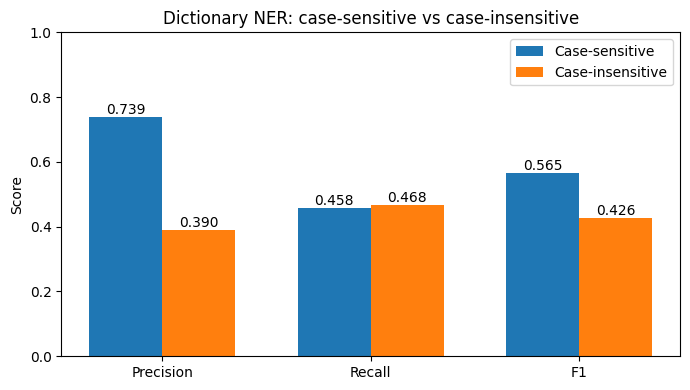

In [11]:
import numpy as np
metrics = ["Precision", "Recall", "F1"]
x = np.arange(len(metrics)); w = 0.35
fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - w/2, [comp.loc[0, m] for m in metrics], w, label="Case-sensitive")
b2 = ax.bar(x + w/2, [comp.loc[1, m] for m in metrics], w, label="Case-insensitive")
ax.bar_label(b1, fmt="%.3f"); ax.bar_label(b2, fmt="%.3f")
ax.set_xticks(x); ax.set_xticklabels(metrics); ax.set_ylim(0, 1); ax.set_ylabel("Score")
ax.set_title("Dictionary NER: case-sensitive vs case-insensitive"); ax.legend()
plt.tight_layout(); plt.savefig("p2_comparison.png", dpi=150); plt.show()

### 2.3 Error analysis: incorrect predictions
Uses the categories defined in the helper cell above.

In [12]:
err_cs = error_table(pred_cs)
err_ci = error_table(pred_ci)
new_in_ci = error_table(pred_ci, only=(pred_ci - gold) - (pred_cs - gold))   # errors that exist ONLY because we ignored case

print(f"False positives: case-sensitive = {len(err_cs)}, case-insensitive = {len(err_ci)}, introduced only by case-insensitivity = {len(new_in_ci)}")

print("\n>>> 10 incorrect predictions: CASE-SENSITIVE")
display(err_cs.head(10))
print(">>> 10 incorrect predictions: CASE-INSENSITIVE")
display(err_ci.head(10))
print(">>> Incorrect predictions that appear ONLY with case-insensitive matching (first 10)")
display(new_in_ci.head(10))

print("Error category breakdown (case-sensitive):")
print(err_cs["Error category"].value_counts().to_string())
print("\nError category breakdown (case-insensitive):")
print(err_ci["Error category"].value_counts().to_string())

assert len(err_cs) >= 5 and len(err_ci) >= 5, "Fewer than five incorrect predictions found"

False positives: case-sensitive = 46, case-insensitive = 208, introduced only by case-insensitivity = 162

>>> 10 incorrect predictions: CASE-SENSITIVE


,Sent,Predicted,Pred type,Error category,Detail,Sentence
0,8,The,LOC,Spurious,no gold entity here (ordinary word/phrase matched),"[[The]] Wallabies ran in five tries with Campese , who has retired from test rugby after collecting 101 caps and a w..."
1,9,MIAMI,LOC,Type confusion,gold type = ORG,[[MIAMI]] 14 4 .778 -
2,11,Des,PER,Boundary error,overlaps gold 'Des Terblanche' [PER],205 [[Des]] Terblanche 65 67 73
3,19,The,LOC,Spurious,no gold entity here (ordinary word/phrase matched),""" [[The]] perspective on growth is such that reasonably we can think that somewhere between 65 and 80 litres per yea..."
4,24,The,LOC,Spurious,no gold entity here (ordinary word/phrase matched),[[The]] BILO stores are located in Malysia 's capital Kuala Lumpur and in the country 's second city Johor Bahru .
5,35,3,ORG,Spurious,no gold entity here (ordinary word/phrase matched),Extremadura 15 1 [[3]] 11 8 30 6
6,38,3,ORG,Spurious,no gold entity here (ordinary word/phrase matched),Real Sociedad 15 7 [[3]] 5 20 18 24
7,47,The,LOC,Spurious,no gold entity here (ordinary word/phrase matched),"[[The]] ministry updated port conditions and shipping warnings for the Gulf of Mexico , Caribbean and Pacific Coast ."
8,47,Gulf,LOC,Boundary error,overlaps gold 'Gulf of Mexico' [LOC],"The ministry updated port conditions and shipping warnings for the [[Gulf]] of Mexico , Caribbean and Pacific Coast ."
9,47,Mexico,LOC,Boundary error,overlaps gold 'Gulf of Mexico' [LOC],"The ministry updated port conditions and shipping warnings for the Gulf of [[Mexico]] , Caribbean and Pacific Coast ."


>>> 10 incorrect predictions: CASE-INSENSITIVE


,Sent,Predicted,Pred type,Error category,Detail,Sentence
0,3,van,LOC,Boundary error,overlaps gold 'Steve van Vuuren' [PER],209 Steve [[van]] Vuuren 65 69 75
1,4,news,ORG,Spurious,no gold entity here (ordinary word/phrase matched),Lieutenant-General Maurice Baril told a [[news]] conference in Nairobi his main concern was for a large group of abo...
2,4,the,LOC,Spurious,no gold entity here (ordinary word/phrase matched),Lieutenant-General Maurice Baril told a news conference in Nairobi his main concern was for a large group of about 1...
3,4,west,LOC,Spurious,no gold entity here (ordinary word/phrase matched),Lieutenant-General Maurice Baril told a news conference in Nairobi his main concern was for a large group of about 1...
4,4,the,LOC,Spurious,no gold entity here (ordinary word/phrase matched),Lieutenant-General Maurice Baril told a news conference in Nairobi his main concern was for a large group of about 1...
5,4,city,ORG,Spurious,no gold entity here (ordinary word/phrase matched),Lieutenant-General Maurice Baril told a news conference in Nairobi his main concern was for a large group of about 1...
6,6,the,LOC,Spurious,no gold entity here (ordinary word/phrase matched),""" A worsening in [[the]] president 's lung functions took place yesterday , "" presidential spokesman Ladlislav Space..."
7,6,said,PER,Spurious,no gold entity here (ordinary word/phrase matched),""" A worsening in the president 's lung functions took place yesterday , "" presidential spokesman Ladlislav Spacek [[..."
8,8,The,LOC,Spurious,no gold entity here (ordinary word/phrase matched),"[[The]] Wallabies ran in five tries with Campese , who has retired from test rugby after collecting 101 caps and a w..."
9,8,jersey,LOC,Spurious,no gold entity here (ordinary word/phrase matched),"The Wallabies ran in five tries with Campese , who has retired from test rugby after collecting 101 caps and a world..."


>>> Incorrect predictions that appear ONLY with case-insensitive matching (first 10)


,Sent,Predicted,Pred type,Error category,Detail,Sentence
0,3,van,LOC,Boundary error,overlaps gold 'Steve van Vuuren' [PER],209 Steve [[van]] Vuuren 65 69 75
1,4,news,ORG,Spurious,no gold entity here (ordinary word/phrase matched),Lieutenant-General Maurice Baril told a [[news]] conference in Nairobi his main concern was for a large group of abo...
2,4,the,LOC,Spurious,no gold entity here (ordinary word/phrase matched),Lieutenant-General Maurice Baril told a news conference in Nairobi his main concern was for a large group of about 1...
3,4,west,LOC,Spurious,no gold entity here (ordinary word/phrase matched),Lieutenant-General Maurice Baril told a news conference in Nairobi his main concern was for a large group of about 1...
4,4,the,LOC,Spurious,no gold entity here (ordinary word/phrase matched),Lieutenant-General Maurice Baril told a news conference in Nairobi his main concern was for a large group of about 1...
5,4,city,ORG,Spurious,no gold entity here (ordinary word/phrase matched),Lieutenant-General Maurice Baril told a news conference in Nairobi his main concern was for a large group of about 1...
6,6,the,LOC,Spurious,no gold entity here (ordinary word/phrase matched),""" A worsening in [[the]] president 's lung functions took place yesterday , "" presidential spokesman Ladlislav Space..."
7,6,said,PER,Spurious,no gold entity here (ordinary word/phrase matched),""" A worsening in the president 's lung functions took place yesterday , "" presidential spokesman Ladlislav Spacek [[..."
8,8,jersey,LOC,Spurious,no gold entity here (ordinary word/phrase matched),"The Wallabies ran in five tries with Campese , who has retired from test rugby after collecting 101 caps and a world..."
9,8,the,LOC,Spurious,no gold entity here (ordinary word/phrase matched),"The Wallabies ran in five tries with Campese , who has retired from test rugby after collecting 101 caps and a world..."


Error category breakdown (case-sensitive):
Error category
Boundary error    22
Spurious          17
Type confusion     7

Error category breakdown (case-insensitive):
Error category
Spurious          171
Boundary error     25
Type confusion     12


### 2.4 Discussion (Problem 2)
Generated from the results above.

In [13]:
cs, ci = comp.iloc[0], comp.iloc[1]
new_tp  = (pred_ci & gold) - (pred_cs & gold)       # entities only case-insensitive found
lost_tp = (pred_cs & gold) - (pred_ci & gold)       # entities only case-sensitive found
spur = new_in_ci[new_in_ci["Error category"] == "Spurious"]
top_spur = ", ".join(f"“{w}” ×{n}" for w, n in spur["Predicted"].str.lower().value_counts().head(6).items())
new_tp_ex = ", ".join(sorted({" ".join(test_sents[sid][0][s:e]) for sid, s, e, t in new_tp})[:4]) or "none"
worst = per[per.Type != "OVERALL (micro)"].assign(p_drop=lambda d: d["Precision (CS)"] - d["Precision (CI)"]).sort_values("p_drop", ascending=False).iloc[0]
winner = "case-sensitive" if cs.F1 >= ci.F1 else "case-insensitive"
dP = (cs.Precision - ci.Precision) * 100
prec_word = "collapses" if dP > 10 else ("drops" if dP > 0 else "does not drop")
verdict = ("on this data the precision loss outweighs the recall gain" if cs.F1 >= ci.F1
           else "on this data the recall gain outweighs the precision loss")

display(Markdown(f"""
* **Result.** Case-sensitive: P = {cs.Precision:.3f}, R = {cs.Recall:.3f}, F1 = {cs.F1:.3f}. Case-insensitive: P = {ci.Precision:.3f}, R = {ci.Recall:.3f}, F1 = {ci.F1:.3f}. The **{winner}** method wins on F1 (difference {abs(cs.F1-ci.F1)*100:.1f} points).
* **Recall gain is tiny.** Ignoring case changes recall by only {(ci.Recall-cs.Recall)*100:+.1f} points ({len(new_tp)} newly found entities, e.g. {new_tp_ex}; {len(lost_tp)} lost). These are entities written in a different case (ALL-CAPS headlines and sports tables) than in training.
* **Precision {prec_word}.** Detected entities rise from {int(cs['Entities detected'])} to {int(ci['Entities detected'])} and false positives from {int(cs.FP)} to {int(ci.FP)}, so precision changes by {-dP:+.1f} points. {len(new_in_ci)} of the false positives exist *only* because case was ignored, and {len(spur)} of those are spurious matches on ordinary words. The most frequent are: {top_spur}. Lowercasing makes common words collide with dictionary entries that came from noisy training annotations or from names that are also ordinary words.
* **Where it hurts most.** {worst.Type} suffers the largest precision drop ({worst['Precision (CS)']:.3f} → {worst['Precision (CI)']:.3f}). Capitalisation is the main cue that separates names from common words in a context-free dictionary matcher, and discarding it throws that cue away.
* **Trade-off.** Case-sensitivity buys precision, case-insensitivity buys recall, and {verdict}. Section 2.5 tests whether a simple filter can keep the recall benefit without the precision cost.
"""))


* **Result.** Case-sensitive: P = 0.739, R = 0.458, F1 = 0.565. Case-insensitive: P = 0.390, R = 0.468, F1 = 0.426. The **case-sensitive** method wins on F1 (difference 14.0 points).
* **Recall gain is tiny.** Ignoring case changes recall by only +1.1 points (6 newly found entities, e.g. ATLANTIC, Ahold, INDIANAPOLIS, Kuala Lumpur; 3 lost). These are entities written in a different case (ALL-CAPS headlines and sports tables) than in training.
* **Precision collapses.** Detected entities rise from 176 to 341 and false positives from 46 to 208, so precision changes by -34.9 points. 162 of the false positives exist *only* because case was ignored, and 154 of those are spurious matches on ordinary words. The most frequent are: “the” ×99, “said” ×24, “city” ×4, “news” ×2, “nine” ×2, “national” ×2. Lowercasing makes common words collide with dictionary entries that came from noisy training annotations or from names that are also ordinary words.
* **Where it hurts most.** LOCATION suffers the largest precision drop (0.761 → 0.355). Capitalisation is the main cue that separates names from common words in a context-free dictionary matcher, and discarding it throws that cue away.
* **Trade-off.** Case-sensitivity buys precision, case-insensitivity buys recall, and on this data the precision loss outweighs the recall gain. Section 2.5 tests whether a simple filter can keep the recall benefit without the precision cost.


### 2.5 Extension: precision filter for noisy dictionary entries
The false positives above come from single-token entries that are far more often **ordinary words** than entities in the training data (e.g. *the*, *said*, *3*). A data-driven filter removes a single-token key if, in the **training set**, it occurs with tag `O` more often than as a whole annotated entity. The filter uses training data only (no test leakage) and is applied to both the case-sensitive and the case-insensitive dictionary.

Case-sensitive:   removed 17 entries, 7206 remain. Examples: ['The', '3', 'Wednesday', 'An', 'Date', 'GOLF', 'BP', 'Interior']
Case-insensitive: removed 79 entries, 6756 remain. Examples: ['the', 'said', '3', 'an', 'wednesday', 'or', 'news', 'city']


Method,Entities detected,Correct (TP),FP,FN,Precision,Recall,F1
Case-sensitive,176,130,46,154,0.7386,0.4577,0.5652
Case-insensitive,341,133,208,151,0.3900,0.4683,0.4256
Case-sensitive + filter,158,130,28,154,0.8228,0.4577,0.5882
Case-insensitive + filter,172,133,39,151,0.7733,0.4683,0.5833


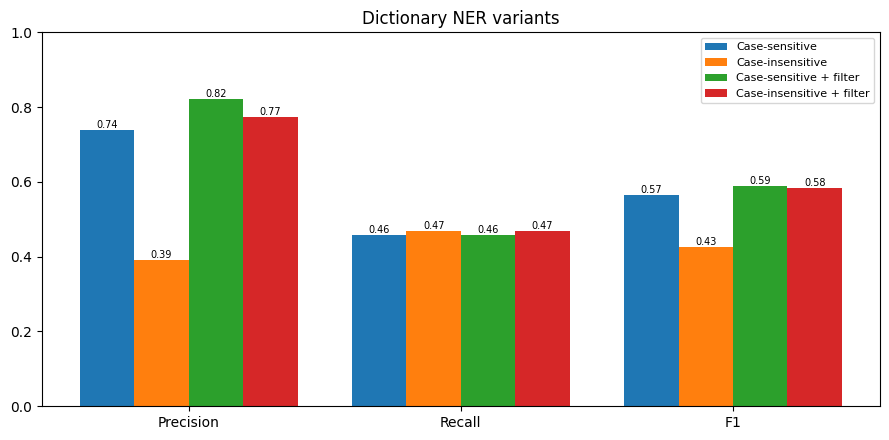


* The filter changes case-sensitive F1 from **0.565** to **0.588** (precision 0.739 → 0.823, recall 0.458 → 0.458) and case-insensitive F1 from **0.426** to **0.583** (precision 0.390 → 0.773).
* The best variant overall is **Case-sensitive + filter** (F1 = 0.588). Removing dictionary entries that are mostly ordinary words repairs much of the precision damage, which supports the view that these false positives are dictionary noise rather than a flaw in longest-match itself.
* Remaining errors are context problems (boundary and type confusion) that a pure dictionary cannot solve.


In [14]:
def filter_lookup(lookup, lower):
    o, e = Counter(), Counter()
    for toks, tags in train_sents:
        for w, t in zip(toks, tags):
            if t == "O": o[(w.lower() if lower else w,)] += 1
    for t, cc in counts.items():
        for ph, n in cc.items():
            if len(ph) == 1:
                e[(ph[0].lower() if lower else ph[0],)] += n
    removed = [k for k in lookup if len(k) == 1 and o[k] > e[k]]
    kept = {k: v for k, v in lookup.items() if k not in set(removed)}
    removed.sort(key=lambda k: -(o[k] - e[k]))
    return kept, removed

lookup_cs_f, rem_cs = filter_lookup(lookup_cs, lower=False)
lookup_ci_f, rem_ci = filter_lookup(lookup_ci, lower=True)
print(f"Case-sensitive:   removed {len(rem_cs)} entries, {len(lookup_cs_f)} remain. Examples: {[k[0] for k in rem_cs[:8]]}")
print(f"Case-insensitive: removed {len(rem_ci)} entries, {len(lookup_ci_f)} remain. Examples: {[k[0] for k in rem_ci[:8]]}")

pred_cs_f = run_ner(test_sents, lookup_cs_f, lower=False)
pred_ci_f = run_ner(test_sents, lookup_ci_f, lower=True)
comp4 = pd.DataFrame([row("Case-sensitive", res_cs), row("Case-insensitive", res_ci),
                      row("Case-sensitive + filter", evaluate(gold, pred_cs_f)),
                      row("Case-insensitive + filter", evaluate(gold, pred_ci_f))])
display(comp4.style.format({"Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}).hide(axis="index"))

x = np.arange(3); w = 0.2
fig, ax = plt.subplots(figsize=(9, 4.5))
for j, (i, lab) in enumerate(zip(range(4), comp4["Method"])):
    bars = ax.bar(x + (j - 1.5) * w, [comp4.loc[i, m] for m in ["Precision", "Recall", "F1"]], w, label=lab)
    ax.bar_label(bars, fmt="%.2f", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(["Precision", "Recall", "F1"]); ax.set_ylim(0, 1); ax.legend(fontsize=8)
ax.set_title("Dictionary NER variants"); plt.tight_layout(); plt.savefig("p2_extension.png", dpi=150); plt.show()

best = comp4.sort_values("F1", ascending=False).iloc[0]
improve_txt = ("which supports the view that these false positives are dictionary noise rather than a flaw in longest-match itself."
               if comp4.iloc[3].F1 > comp4.iloc[1].F1 else
               "although here the filter gives no F1 gain for the case-insensitive dictionary, so the remaining errors are not simple single-word noise.")
b_cs, b_ci = comp4.iloc[2], comp4.iloc[3]
display(Markdown(f"""
* The filter changes case-sensitive F1 from **{comp4.iloc[0].F1:.3f}** to **{b_cs.F1:.3f}** (precision {comp4.iloc[0].Precision:.3f} → {b_cs.Precision:.3f}, recall {comp4.iloc[0].Recall:.3f} → {b_cs.Recall:.3f}) and case-insensitive F1 from **{comp4.iloc[1].F1:.3f}** to **{b_ci.F1:.3f}** (precision {comp4.iloc[1].Precision:.3f} → {b_ci.Precision:.3f}).
* The best variant overall is **{best.Method}** (F1 = {best.F1:.3f}). Removing dictionary entries that are mostly ordinary words repairs much of the precision damage, {improve_txt}
* Remaining errors are context problems (boundary and type confusion) that a pure dictionary cannot solve.
"""))

# Problem 3: Unigram frequency analysis of WikiText-2

`wikitext-2-raw-v1` (train split) is used because the raw version has no `<unk>` replacement, so every real word is counted.

**Pre-processing details (important for correct counts):**
* WikiText marks tokenisation artefacts such as `@-@`, `@,@`, `@.@` inside numbers/hyphenated words; these are restored (`1 @,@ 000 -> 1,000`, `well @-@ known -> well-known`).
* WikiText also splits contractions and possessives into separate tokens (`king 's`, `did n't`). If left alone, a stray token **`s`** would appear as one of the most frequent “words”. They are re-attached to the preceding word (`king's`, `didn't`) before tokenising.
* The tokeniser is Unicode-aware (accented letters are kept) and punctuation is excluded.

**Pipeline:** read train text -> lowercase -> re-attach clitics and restore `@` artefacts -> tokenise -> count -> probability `P(w) = count(w) / N`.

In [15]:
wt = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
lines = [l for l in wt["text"] if l.strip()]
print(f"Non-empty lines in WikiText-2 train: {len(lines)}")

text = " ".join(lines).lower()                                                   # lowercase
text = re.sub(r"\s+(n't|'s|'re|'ve|'ll|'d|'m)(?=\s|$)", r"\1", text)             # re-attach clitics / possessives
text = text.replace(" @-@ ", "-").replace(" @,@ ", ",").replace(" @.@ ", ".")    # restore number/hyphen artefacts
TOKEN_RE = re.compile(r"[^\W_]+(?:['’.,-][^\W_]+)*")                               # unicode words/numbers, no punctuation
tokens = TOKEN_RE.findall(text)

freq = Counter(tokens)                                                           # frequency of every word
N, V = len(tokens), len(freq)
hapax = sum(1 for c in freq.values() if c == 1)
print(f"Total tokens N = {N:,} | Vocabulary size V = {V:,} | Hapax legomena (freq = 1): {hapax:,} ({hapax / V:.1%} of vocabulary)")
assert sum(freq.values()) == N
assert "s" not in [w for w, _ in freq.most_common(20)], "stray possessive token 's' still in top 20"

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Non-empty lines in WikiText-2 train: 23767
Total tokens N = 1,712,208 | Vocabulary size V = 78,611 | Hapax legomena (freq = 1): 36,038 (45.8% of vocabulary)


### 3.1 Word-frequency table

In [16]:
freq_df = pd.DataFrame(freq.most_common(), columns=["Word", "Frequency"])
freq_df.insert(0, "Rank", range(1, len(freq_df) + 1))
freq_df["P(word)"] = freq_df["Frequency"] / N
freq_df.to_csv("wikitext2_word_frequencies.csv", index=False)
print(f"Full table ({len(freq_df):,} rows) saved to wikitext2_word_frequencies.csv. Top 20:")
top20 = freq_df.head(20)
display(top20.style.format({"Frequency": "{:,}", "P(word)": "{:.6f}"}).hide(axis="index"))

Full table (78,611 rows) saved to wikitext2_word_frequencies.csv. Top 20:


Rank,Word,Frequency,P(word)
1,the,"130,715",0.076343
2,of,"56,963",0.033269
3,and,"50,646",0.029579
4,in,"44,843",0.026190
5,to,"39,413",0.023019
6,a,"36,340",0.021224
7,was,"21,008",0.012270
8,as,"15,051",0.008790
9,on,"15,044",0.008786
10,that,"14,278",0.008339


### 3.2 Unigram probabilities of five selected words

In [17]:
selected = ["the", "of", "university", "war", "album"]
prob_df = pd.DataFrame({
    "Word": selected,
    "Count": [freq[w] for w in selected],
    "N": N,
    "P(w) = Count / N": [freq[w] / N for w in selected],
})
display(prob_df.style.format({"Count": "{:,}", "N": "{:,}", "P(w) = Count / N": "{:.8f}"}).hide(axis="index"))

# sanity check: a valid unigram model sums to 1
print("Sum of P(w) over the whole vocabulary =", round(sum(c / N for c in freq.values()), 10))
# note on unseen words (zero-probability problem), add-one smoothing:
unseen = "zzyzx"
print(f"Unseen word '{unseen}': MLE P = {freq[unseen]/N}, add-one smoothed P = {(freq[unseen]+1)/(N+V):.3e}")

# unigram sentence probability: P(sentence) = prod P(w_i)  (computed in log space to avoid underflow)
sent = "the war album was released".split()
logp_mle = sum(math.log(freq[w] / N) for w in sent if freq[w] > 0)
logp_add1 = sum(math.log((freq[w] + 1) / (N + V)) for w in sent)
print(f"Sentence: {' '.join(sent)!r}")
print(f"MLE log P = {logp_mle:.3f} -> P = {math.exp(logp_mle):.3e}  (all words seen: {all(freq[w] > 0 for w in sent)})")
print(f"Add-one log P = {logp_add1:.3f} -> P = {math.exp(logp_add1):.3e}")

Word,Count,N,P(w) = Count / N
the,"130,715","1,712,208",0.07634294
of,"56,963","1,712,208",0.03326874
university,549,"1,712,208",0.00032064
war,"1,303","1,712,208",0.00076101
album,"1,253","1,712,208",0.00073180


Sum of P(w) over the whole vocabulary = 1.0
Unseen word 'zzyzx': MLE P = 0.0, add-one smoothed P = 5.584e-07
Sentence: 'the war album was released'
MLE log P = -28.857 -> P = 2.934e-13  (all words seen: True)
Add-one log P = -29.079 -> P = 2.350e-13


### 3.3 Bar chart of the 20 most frequent words

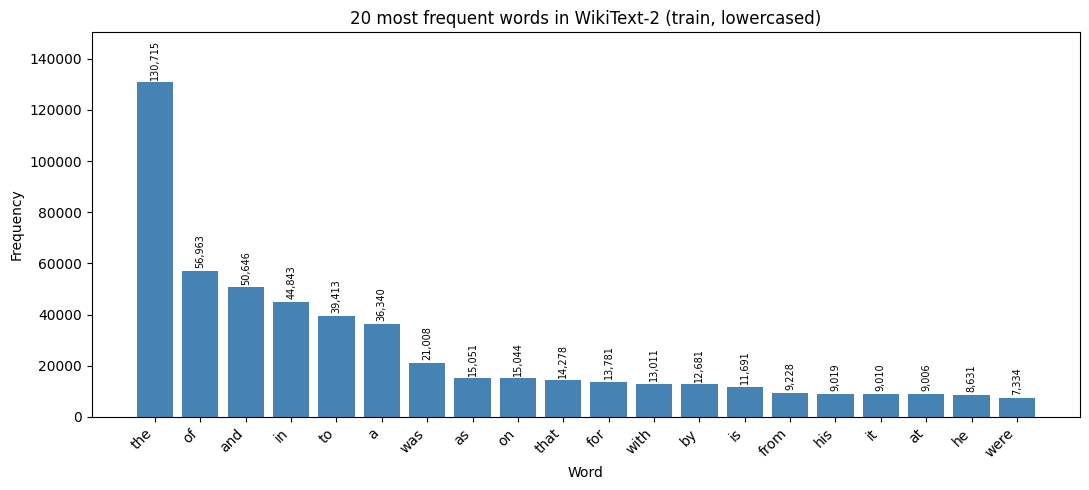

In [18]:
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(top20["Word"], top20["Frequency"], color="steelblue")
ax.bar_label(bars, labels=[f"{v:,}" for v in top20["Frequency"]], fontsize=7, rotation=90, padding=2)
ax.set_xlabel("Word"); ax.set_ylabel("Frequency")
ax.set_title("20 most frequent words in WikiText-2 (train, lowercased)")
plt.xticks(rotation=45, ha="right"); ax.set_ylim(0, top20["Frequency"].max() * 1.15)
plt.tight_layout(); plt.savefig("wikitext2_top20.png", dpi=150); plt.show()

### 3.4 Zipf's law check (rank-frequency, log-log)

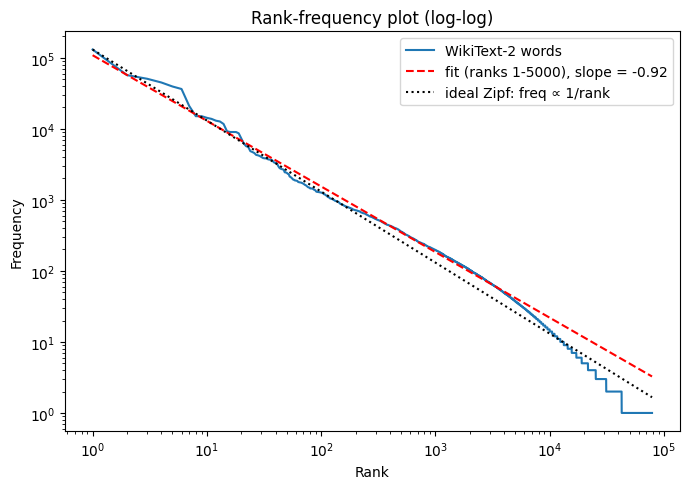

Fitted log-log slope = -0.924 (Zipf's law predicts about -1)


In [19]:
fr = np.array([c for _, c in freq.most_common()], dtype=float)
ranks = np.arange(1, len(fr) + 1)
k = min(5000, len(fr))
slope, intercept = np.polyfit(np.log10(ranks[:k]), np.log10(fr[:k]), 1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(ranks, fr, label="WikiText-2 words")
ax.loglog(ranks, 10 ** intercept * ranks ** slope, "r--", label=f"fit (ranks 1-{k}), slope = {slope:.2f}")
ax.loglog(ranks, fr[0] / ranks, "k:", label="ideal Zipf: freq ∝ 1/rank")
ax.set_xlabel("Rank"); ax.set_ylabel("Frequency"); ax.set_title("Rank-frequency plot (log-log)")
ax.legend(); plt.tight_layout(); plt.savefig("wikitext2_zipf.png", dpi=150); plt.show()
print(f"Fitted log-log slope = {slope:.3f} (Zipf's law predicts about -1)")

### 3.5 Discussion (Problem 3)
Generated from the results above.

In [20]:
top20_share = top20["Frequency"].sum() / N
once_tokens = hapax / N
display(Markdown(f"""
* **Function words dominate.** The 20 most frequent words (*{', '.join(top20['Word'].head(10))}, ...*) are determiners, prepositions, conjunctions, auxiliaries and pronouns. Together they make up **{top20_share:.1%}** of all {N:,} tokens, while the single word “{top20.iloc[0].Word}” alone accounts for {top20.iloc[0]['P(word)']:.1%}.
* **Zipf's law holds.** On the log-log plot the rank-frequency curve is close to a straight line with fitted slope **{slope:.2f}** (Zipf predicts about −1). The tail is very long: **{hapax:,} of {V:,} word types ({hapax / V:.1%})** occur exactly once, yet they are only {once_tokens:.1%} of the running text.
* **Unigram model.** `P(sentence) = ∏ P(w_i)` ignores word order and context, so *“the war album was released”* and any permutation of it receive the same probability. It is the baseline that bigram and higher n-gram models improve on.
* **Zero-probability problem.** MLE gives probability 0 to any unseen word, which would zero out a whole sentence (the demo word *zzyzx* has P = 0). Add-one smoothing gives it P = {(0 + 1) / (N + V):.2e}, at the cost of taking a little mass from seen words. With {hapax / V:.0%} of types seen only once, unseen words are common in practice, so smoothing is necessary.
* **Tokenisation choices change the counts.** Re-attaching WikiText's split clitics (*king 's → king's*) removes a spurious token “s” that would otherwise rank in the top 10, and excluding punctuation keeps the list to real words. Different choices (case folding, number handling, hyphens) would give different N, V and probabilities.
"""))


* **Function words dominate.** The 20 most frequent words (*the, of, and, in, to, a, was, as, on, that, ...*) are determiners, prepositions, conjunctions, auxiliaries and pronouns. Together they make up **30.8%** of all 1,712,208 tokens, while the single word “the” alone accounts for 7.6%.
* **Zipf's law holds.** On the log-log plot the rank-frequency curve is close to a straight line with fitted slope **-0.92** (Zipf predicts about −1). The tail is very long: **36,038 of 78,611 word types (45.8%)** occur exactly once, yet they are only 2.1% of the running text.
* **Unigram model.** `P(sentence) = ∏ P(w_i)` ignores word order and context, so *“the war album was released”* and any permutation of it receive the same probability. It is the baseline that bigram and higher n-gram models improve on.
* **Zero-probability problem.** MLE gives probability 0 to any unseen word, which would zero out a whole sentence (the demo word *zzyzx* has P = 0). Add-one smoothing gives it P = 5.58e-07, at the cost of taking a little mass from seen words. With 46% of types seen only once, unseen words are common in practice, so smoothing is necessary.
* **Tokenisation choices change the counts.** Re-attaching WikiText's split clitics (*king 's → king's*) removes a spurious token “s” that would otherwise rank in the top 10, and excluding punctuation keeps the list to real words. Different choices (case folding, number handling, hyphens) would give different N, V and probabilities.


## Summary of results

In [21]:
o1 = res1[res1.Type == "OVERALL (micro)"].iloc[0]
display(Markdown(f"""
| Problem | Key result |
|---|---|
| 1. Dictionary NER (case-sensitive, longest match) | P = {o1.Precision:.3f}, R = {o1.Recall:.3f}, F1 = {o1.F1:.3f} on 200 unseen test sentences |
| 2. Case-sensitive vs case-insensitive | F1 {comp.iloc[0].F1:.3f} vs {comp.iloc[1].F1:.3f}; with precision filter {comp4.iloc[2].F1:.3f} vs {comp4.iloc[3].F1:.3f} |
| 3. WikiText-2 unigram model | N = {N:,}, V = {V:,}; most frequent word “{top20.iloc[0].Word}” (P = {top20.iloc[0]['P(word)']:.4f}); Zipf slope {slope:.2f} |
"""))


| Problem | Key result |
|---|---|
| 1. Dictionary NER (case-sensitive, longest match) | P = 0.739, R = 0.458, F1 = 0.565 on 200 unseen test sentences |
| 2. Case-sensitive vs case-insensitive | F1 0.565 vs 0.426; with precision filter 0.588 vs 0.583 |
| 3. WikiText-2 unigram model | N = 1,712,208, V = 78,611; most frequent word “the” (P = 0.0763); Zipf slope -0.92 |
